<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and source details](README.md)

# 01 · Can inflation slow while the price index stays elevated?

An inflation rate describes a change in a price index; it is not the index level. We will retrieve a bounded historical CPI window, plot both quantities separately, and change the displayed reference month to see which conclusions depend on that reference.

The data come **live from the official BLS Public Data API**, through the real published Python worker. One request retrieves 2019–2024 observations for two CPI-U series. We retain source value text and footnotes and materialize the response once per run. No synthetic or cached fallback is substituted if BLS rejects the request.

## Choose the display reference month

`BASE_MONTH` is the month whose displayed index becomes 100. It does not change BLS data or the official 1982–84 reference base. Choose a first-of-month date within the fetched 2019–2024 window. Dates label **monthly observation periods**, not release dates or instants in UTC.

The experiment changes only **2019-12-01 → 2021-12-01**. Predict different rebased levels but identical 12-month percentage changes. Restart the kernel and Run All after editing; each run makes one bounded data request, subject to BLS availability and quota.

In [1]:
BASE_MONTH = "2019-12-01"  # Monthly reference; experiment: "2021-12-01"

In [2]:
import hashlib
import json
import os
from datetime import date, datetime, timezone

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

base=date.fromisoformat(BASE_MONTH)
assert base.day==1 and date(2019,1,1)<=base<=date(2024,12,1)
# Select the documented public, unregistered path explicitly.
for name in ("BLS_API_KEY","BLS_ALLOW_INSECURE_HTTP","VGI_BEARER_TOKENS"):
    os.environ.pop(name,None)
os.environ["BLS_API_BASE_URL"]="https://api.bls.gov/publicAPI/v2"
os.environ["PLOOMBER_STATS_ENABLED"]="false"
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":125,"text.parse_math":False,"axes.spines.top":False,"axes.spines.right":False})
LABELS={"CUUR0000SA0":"All items","CUUR0000SA0L1E":"Less food and energy"}
COLORS={"CUUR0000SA0":"#247f9e","CUUR0000SA0L1E":"#b88a29"}
def prose(text):display(Markdown(text))
def finish(fig):
    fig.text(.01,.01,f"Source: BLS CPI-U · U.S. city average · not seasonally adjusted · retrieved {retrieved_at[:10]} UTC",fontsize=8,color="#555555")
    fig.tight_layout(rect=(0,.05,1,.96));plt.show()
con=haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline


/Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-bls/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-bls/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-bls/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-bls/notebooks/pyproject.toml.

## Attach a pinned, portable worker

The Git tag is remotely available; `uvx` installs the worker outside this checkout. The SDK and RPC versions match its tested release. This public path needs no registration key. Optional catalog metadata and registered-only features are left off.

| BLS series | Measure | Units and adjustment |
|---|---|---|
| [`CUUR0000SA0`](https://data.bls.gov/timeseries/CUUR0000SA0) | CPI-U, all items, U.S. city average | Index 1982–84=100, not seasonally adjusted |
| [`CUUR0000SA0L1E`](https://data.bls.gov/timeseries/CUUR0000SA0L1E) | CPI-U, all items less food and energy, U.S. city average | Index 1982–84=100, not seasonally adjusted |

These are aggregate indexes, not household-specific expenses. BLS explains their coverage and seasonal adjustment in its [CPI FAQ](https://www.bls.gov/cpi/questions-and-answers.htm). We compare the same month a year apart rather than interpreting unadjusted month-to-month changes as a short-term trend.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'bls' AS bls (
    TYPE vgi,
    LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-bls@v0.1.0 --with vgi-python==0.51.1 --with vgi-rpc==0.53.1 vgi-bls-worker'
);

,Success


## Fetch once, with the request bounded by arguments

The years **2019 and 2024 are inclusive**. Both series are requested together, and the extra 2019 observations supply prior-year comparisons for the displayed 2020–2024 window. `max_rows` is an output guard; it does not bound or reduce an upstream request. The ID list and year arguments do that.

BLS period codes are preserved. Only `M01`–`M12` will become monthly dates; `M13`, if present, is an annual average and must not become a thirteenth month. The saved result is what BLS returned at retrieval time, not a reconstructed historical release vintage.

In [4]:
request_started=datetime.now(timezone.utc).isoformat()

In [5]:
%%sql
CREATE TABLE source_observations AS
SELECT * FROM bls.main.observations(
    ['CUUR0000SA0','CUUR0000SA0L1E'],2019,2024,
    annual_average := false,calculations := false,aspects := false,
    include_catalog := false,max_rows := 1000
);

,Count


In [6]:
retrieved_at=datetime.now(timezone.utc).isoformat()

In [7]:
%%sql availability <<
SELECT series_id,count(*) AS rows,
       count(DISTINCT (year,period)) AS distinct_periods,
       min(year) AS first_year,max(year) AS last_year,
       count(*) FILTER (WHERE regexp_full_match(period,'M(0[1-9]|1[0-2])')) AS monthly_rows,
       count(*) FILTER (WHERE NOT regexp_full_match(period,'M(0[1-9]|1[0-2])')) AS nonmonthly_rows,
       count(*) FILTER (WHERE value IS NULL) AS unavailable_values
FROM source_observations GROUP BY series_id ORDER BY series_id;

In [8]:
display(availability)
assert set(availability.series_id)==set(LABELS), "A requested series is unavailable"
assert (availability.rows==availability.distinct_periods).all()
assert (availability.first_year>=2019).all() and (availability.last_year<=2024).all()
source_rows=con.execute("SELECT series_id,year,period,value_text,footnotes_json FROM source_observations ORDER BY series_id,year,period").fetchall()
source_hash=hashlib.sha256(json.dumps(source_rows,separators=(",",":"),ensure_ascii=False).encode()).hexdigest()
prose(f"**Retrieval interval:** {request_started} to {retrieved_at}. "
      f"The response contains **{int(availability.rows.sum())} observations**, including "
      f"**{int(availability.monthly_rows.sum())} monthly rows** and **{int(availability.unavailable_values.sum())} unavailable values**. "
      f"**Source fingerprint:** `{source_hash}`. Footnotes and original value text contribute to that fingerprint. "
      "This is retrieval provenance; BLS does not provide a publication timestamp for each row here.")

,series_id,rows,distinct_periods,first_year,last_year,monthly_rows,nonmonthly_rows,unavailable_values
0,CUUR0000SA0,72,72,2019,2024,72,0,0
1,CUUR0000SA0L1E,72,72,2019,2024,72,0,0


**Retrieval interval:** 2026-11-14T05:28:14.944900+00:00 to 2026-11-14T05:28:15.414912+00:00. The response contains **144 observations**, including **144 monthly rows** and **0 unavailable values**. **Source fingerprint:** `a322dfb0894654aabb3bfb2fb9103e2faf4b672bb6d4cad6d90d2cc1a4b68898`. Footnotes and original value text contribute to that fingerprint. This is retrieval provenance; BLS does not provide a publication timestamp for each row here.

## Build an explicit monthly grid and retain gaps

A calendar grid makes an absent month visible. A left join retains missing values as NULL; plots will break at a gap rather than join across it. The 12-month comparison below joins on the **calendar date minus one year**, avoiding a misleading 12-row lag if months are missing.

Footnotes remain available beside the measurements. Empty footnote objects are not annotations.

In [9]:
%%sql
CREATE TABLE monthly AS
WITH parsed AS (
    SELECT series_id,make_date(year::INTEGER,substr(period,2)::INTEGER,1) AS month,
           value,value_text,footnotes_json
    FROM source_observations WHERE regexp_full_match(period,'M(0[1-9]|1[0-2])')
), grid AS (
    SELECT series_id,month::DATE AS month
    FROM (VALUES ('CUUR0000SA0'),('CUUR0000SA0L1E')) s(series_id)
    CROSS JOIN generate_series(DATE '2019-01-01',DATE '2024-12-01',INTERVAL '1 month') d(month)
)
SELECT g.*,p.value,p.value_text,p.footnotes_json,p.month IS NOT NULL AS source_row_present
FROM grid g LEFT JOIN parsed p USING(series_id,month);

CREATE TABLE metrics AS
SELECT c.*,b.value AS base_value,
       100*c.value/nullif(b.value,0) AS rebased_index,
       100*(c.value/nullif(y.value,0)-1) AS yoy_pct
FROM monthly c
LEFT JOIN monthly b ON b.series_id=c.series_id AND b.month=DATE '{{BASE_MONTH}}'
LEFT JOIN monthly y ON y.series_id=c.series_id AND y.month=c.month-INTERVAL '1 year';

,Count


In [10]:
%%sql coverage <<
SELECT series_id,count(*) AS calendar_months,
       count(*) FILTER (WHERE NOT source_row_present) AS absent_months,
       count(*) FILTER (WHERE value IS NULL) AS unavailable_months,
       count(DISTINCT base_value) AS available_base_values,
       max(abs(rebased_index-100)) FILTER (WHERE month=DATE '{{BASE_MONTH}}') AS base_error
FROM metrics GROUP BY series_id ORDER BY series_id;

In [11]:
%%sql annotations <<
SELECT series_id,month,n.value->>'code' AS code,n.value->>'text' AS note
FROM monthly, json_each(footnotes_json) n
WHERE coalesce(n.value->>'code','')<>'' OR coalesce(n.value->>'text','')<>''
ORDER BY series_id,month,code;

In [12]:
display(coverage);display(annotations)
assert (coverage.available_base_values==1).all(), "Reference month unavailable; choose an observed month"
assert (coverage.base_error<1e-10).all()
prose(f"The grid exposes **{int(coverage.absent_months.sum())} absent months** and "
      f"**{int(coverage.unavailable_months.sum())} unavailable monthly values**. "
      f"There are **{len(annotations)} nonempty source annotations**. The reference month is available for both series and maps to 100.")

,series_id,calendar_months,absent_months,unavailable_months,available_base_values,base_error
0,CUUR0000SA0,72,0,0,1,0.0
1,CUUR0000SA0L1E,72,0,0,1,0.0


,series_id,month,code,note


The grid exposes **0 absent months** and **0 unavailable monthly values**. There are **0 nonempty source annotations**. The reference month is available for both series and maps to 100.

## Price-index levels relative to the selected month

Rebasing divides each observation by that series' value in `BASE_MONTH`, then multiplies by 100. It preserves proportional changes within a series. A value of 120 means the index is 20% above its selected reference month; it does not mean the average household spends exactly 20% more.

In [13]:
%%sql plot_data <<
SELECT series_id,month,value,rebased_index,yoy_pct
FROM metrics WHERE month>=DATE '2020-01-01' ORDER BY series_id,month;

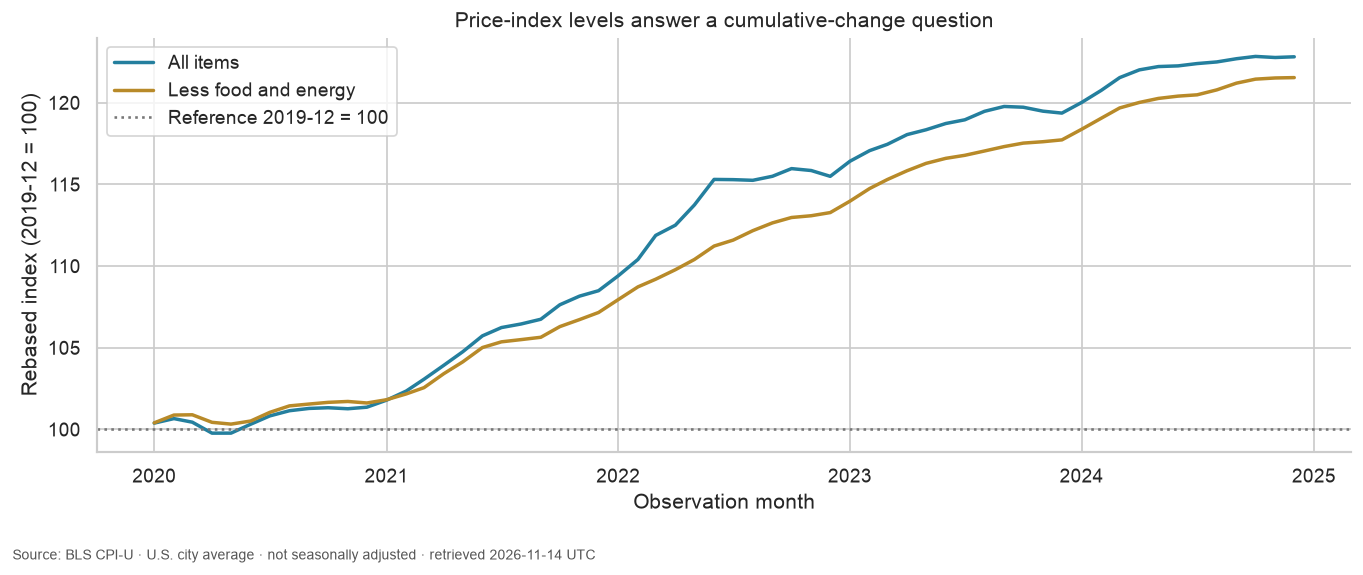

In [14]:
fig,ax=plt.subplots(figsize=(11,4.8))
for sid,group in plot_data.groupby("series_id",sort=False):
    ax.plot(group.month,group.rebased_index,color=COLORS[sid],label=LABELS[sid],linewidth=2)
ax.axhline(100,color="#777777",linestyle=":",label=f"Reference {BASE_MONTH[:7]} = 100")
ax.set(xlabel="Observation month",ylabel=f"Rebased index ({BASE_MONTH[:7]} = 100)",
       title="Price-index levels answer a cumulative-change question")
ax.legend(loc="upper left");finish(fig)

## Twelve-month rates answer a different question

The rate is `100 × (index_t / index_same_month_last_year − 1)`. It does not use the display reference month. A lower positive rate still means the index is above its year-earlier level. Negative rates mean it is below that year-earlier level; neither statement alone determines the level relative to `BASE_MONTH`.

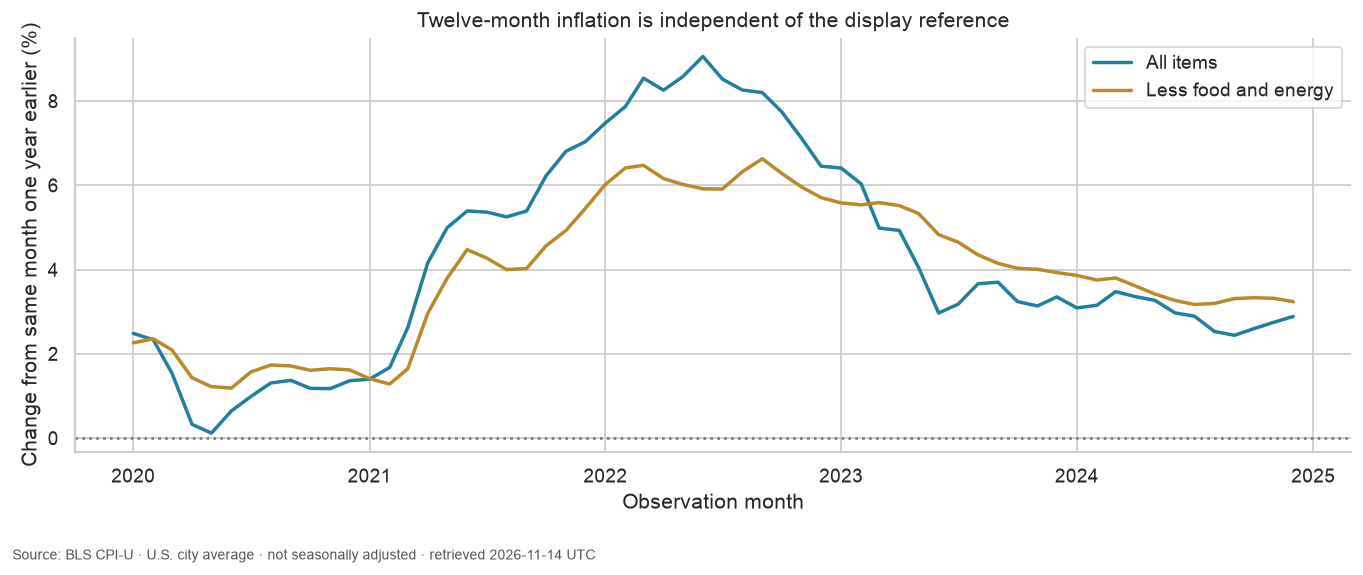

In [15]:
fig,ax=plt.subplots(figsize=(11,4.8))
for sid,group in plot_data.groupby("series_id",sort=False):
    ax.plot(group.month,group.yoy_pct,color=COLORS[sid],label=LABELS[sid],linewidth=2)
ax.axhline(0,color="#777777",linestyle=":")
ax.set(xlabel="Observation month",ylabel="Change from same month one year earlier (%)",
       title="Twelve-month inflation is independent of the display reference")
ax.legend(loc="upper right");finish(fig)

In [16]:
%%sql endpoints <<
WITH peaks AS (
    SELECT series_id,month AS peak_month,yoy_pct AS peak_yoy,
           row_number() OVER (PARTITION BY series_id ORDER BY yoy_pct DESC NULLS LAST,month) AS rn
    FROM metrics WHERE month BETWEEN DATE '2020-01-01' AND DATE '2024-12-01'
)
SELECT m.series_id,m.month,m.value AS official_index,m.rebased_index,
       m.rebased_index-100 AS change_since_base_pct,m.yoy_pct,p.peak_month,p.peak_yoy
FROM metrics m JOIN peaks p ON m.series_id=p.series_id AND p.rn=1
WHERE m.month=DATE '2024-12-01' ORDER BY m.series_id;

In [17]:
display(endpoints)
for _,r in endpoints.iterrows():
    if pd.notna(r.yoy_pct) and pd.notna(r.rebased_index):
        prose(f"**{LABELS[r.series_id]}**, {r.month:%Y-%m}: the index is **{r.change_since_base_pct:+.2f}%** relative to "
              f"{BASE_MONTH[:7]}, while its 12-month change is **{r.yoy_pct:+.2f}%**. "
              f"The highest observed 12-month rate in the displayed window was **{r.peak_yoy:.2f}%** in **{r.peak_month:%Y-%m}**.")
    else:
        prose(f"**{LABELS[r.series_id]}**: the endpoint comparison is unavailable; no missing value is replaced with zero.")
# The year-over-year ratio must agree before and after rebasing wherever both exist.
residual=con.execute("""SELECT max(abs(c.yoy_pct-100*(c.rebased_index/nullif(p.rebased_index,0)-1)))
FROM metrics c JOIN metrics p ON p.series_id=c.series_id AND p.month=c.month-INTERVAL '1 year'""").fetchone()[0]
assert residual is not None and residual<1e-10
rate_rows=con.execute("SELECT series_id,month,yoy_pct FROM metrics ORDER BY series_id,month").fetchall()
rate_hash=hashlib.sha256(repr(rate_rows).encode()).hexdigest()
prose(f"**Rebasing invariant passed:** the maximum rate discrepancy is {residual:.2e} percentage points. "
      f"**Rate fingerprint:** `{rate_hash}`. Compare it with the experiment alongside the source fingerprint.")

,series_id,month,official_index,rebased_index,change_since_base_pct,yoy_pct,peak_month,peak_yoy
0,CUUR0000SA0,2024-12-01,315.605,122.815927,22.815927,2.888057,2022-06-01,9.059758
1,CUUR0000SA0L1E,2024-12-01,322.007,121.541888,21.541888,3.238145,2022-09-01,6.630604


**All items**, 2024-12: the index is **+22.82%** relative to 2019-12, while its 12-month change is **+2.89%**. The highest observed 12-month rate in the displayed window was **9.06%** in **2022-06**.

**Less food and energy**, 2024-12: the index is **+21.54%** relative to 2019-12, while its 12-month change is **+3.24%**. The highest observed 12-month rate in the displayed window was **6.63%** in **2022-09**.

**Rebasing invariant passed:** the maximum rate discrepancy is 2.22e-14 percentage points. **Rate fingerprint:** `e52a44fdf4a0f4cd9a645c7721973ca45c665d3d98c83274e04748d67f68eb62`. Compare it with the experiment alongside the source fingerprint.

## One change to test

Change only **`BASE_MONTH` from `"2019-12-01"` to `"2021-12-01"`**. Compare the first chart and endpoint changes; then confirm that the second chart, year-over-year values and rate fingerprint remain unchanged **if the retrieved source fingerprint matches**. A different source fingerprint means the input changed too, so the comparison is no longer a pure rebasing experiment.

Restore **`"2019-12-01"`** afterward. The [README](README.md) provides the separate-output command. This bounded historical view is descriptive: it does not attribute causes, forecast inflation, reconstruct earlier data vintages or measure each household's cost of living.

In [18]:
con.execute("DETACH bls")
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and source details](README.md)